In [1]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import silhouette_score

from sklearn.metrics import pairwise_distances

In [2]:
class KMedoids:
    
    def __init__(self, n_clusters=5, max_iter=100, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state


    def fit_predict(self, X):

        np.random.seed(self.random_state)

        n_samples = X.shape[0]

        # Random initial medoids
        self.medoids = np.random.choice(
            n_samples,
            self.n_clusters,
            replace=False
        )

        distances = pairwise_distances(X)


        for _ in range(self.max_iter):

            # Assign points to nearest medoid
            labels = np.argmin(
                distances[:, self.medoids],
                axis=1
            )


            old_medoids = self.medoids.copy()


            # Update medoids
            for cluster in range(self.n_clusters):

                cluster_points = np.where(
                    labels == cluster
                )[0]


                if len(cluster_points) == 0:
                    continue


                cluster_distances = distances[
                    np.ix_(
                        cluster_points,
                        cluster_points
                    )
                ]


                costs = cluster_distances.sum(axis=1)


                self.medoids[cluster] = (
                    cluster_points[
                        np.argmin(costs)
                    ]
                )


            if np.array_equal(
                old_medoids,
                self.medoids
            ):
                break


        self.labels_ = np.argmin(
            distances[:, self.medoids],
            axis=1
        )


        return self.labels_

In [3]:
df = pd.read_excel(r"C:\Users\user\Downloads\Mall_Customers-Copy1.csv.xlsx")
print(df.shape)

(200, 5)


In [4]:
df = df.drop(columns=['CustomerID'])

In [5]:
#Encode Gender (optional)

df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

In [34]:
# 4. Select features for scaling

features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values         ]

In [35]:
# 5. Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


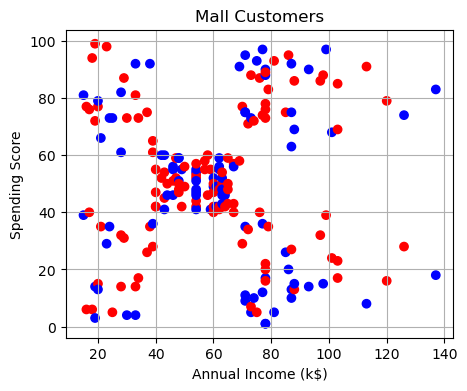

In [6]:
# Scatter Plot
plt.figure(figsize=(5,4))
plt.scatter(df["Annual Income (k$)"],
            df["Spending Score (1-100)"],
            color=df["Gender"].map({1: "blue", 0: "red"}))

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Mall Customers")
plt.grid(True)
plt.show()

In [37]:
best_k = 5

kmedoids = KMedoids(n_clusters=best_k)


kmedoids_labels = kmedoids.fit_predict(X_scaled)

In [38]:
medoids = X_scaled[
    kmedoids.medoids
]

In [39]:
kmeans = KMeans(n_clusters=5,random_state=42,n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

centers = kmeans.cluster_centers_

C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [40]:
# 5. Find optimal K (2-10)
inertia = []
silhouette = []

K = range(2,11)

for k in K:
    km = KMeans(n_clusters=k,random_state=42,n_init=10)

    labels = km.fit_predict(X_scaled)

    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

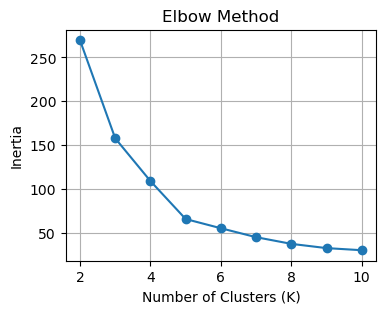

In [41]:
# Elbow Plot
plt.figure(figsize=(4,3))
plt.plot(K, inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

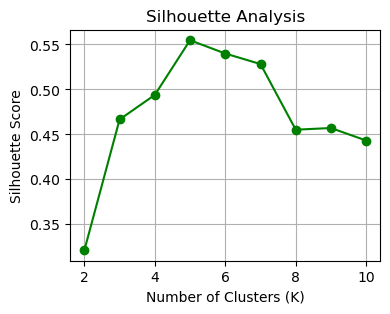

In [42]:
# Silhouette Plot
plt.figure(figsize=(4,3))
plt.plot(K, silhouette, marker='o', color='green')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()

In [43]:
print("Silhouette Scores")
for k, score in zip(K, silhouette):
    print(f"K={k}: {score:.3f}")

best_k = K[np.argmax(silhouette)]
print("Chosen K =", best_k)
print("Highest Silhouette Score:", max(silhouette))

Silhouette Scores
K=2: 0.321
K=3: 0.467
K=4: 0.494
K=5: 0.555
K=6: 0.540
K=7: 0.528
K=8: 0.455
K=9: 0.457
K=10: 0.443
Chosen K = 5
Highest Silhouette Score: 0.5546571631111091


In [46]:
# 7. K-Means

kmeans = KMeans(n_clusters=best_k,random_state=42,n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)



C:\Users\user\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [47]:
# 8. K-Medoids

kmedoids = KMedoids(n_clusters=best_k,random_state=42)

kmedoids_labels = kmedoids.fit_predict(X_scaled)


In [48]:
kmedoids_points = X_scaled[
    kmedoids.medoids
]

C:\Users\user\AppData\Local\Temp\ipykernel_2220\3015469918.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend()


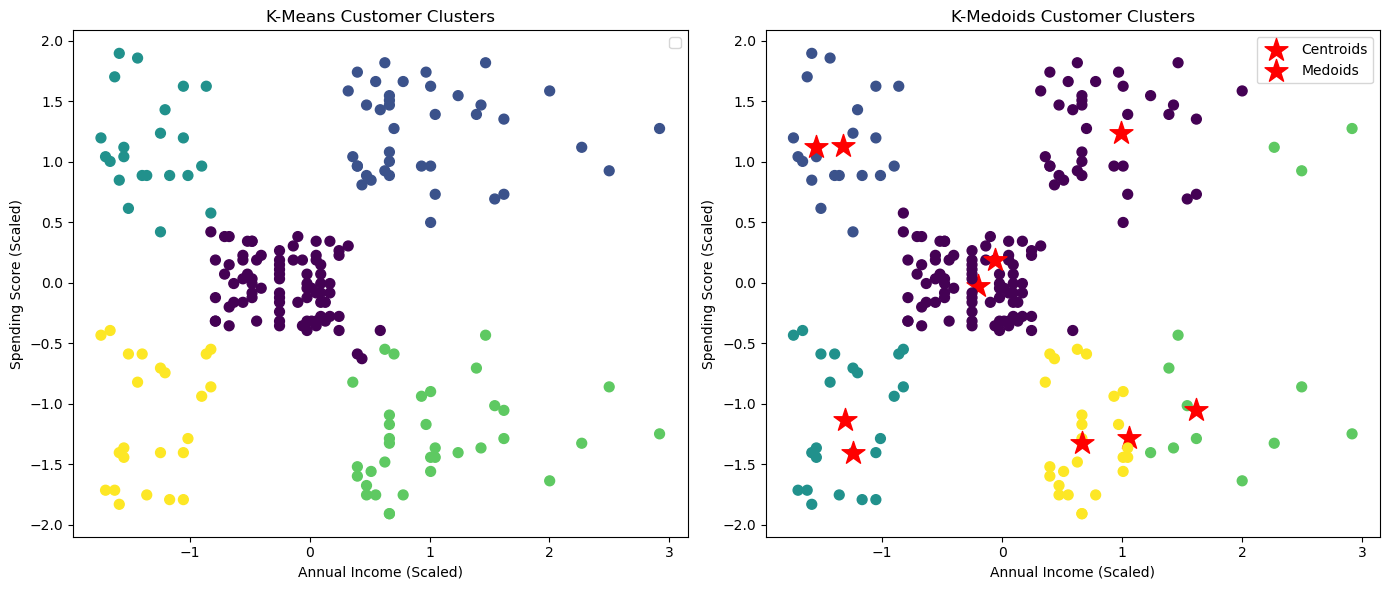

In [49]:
#Side-by-Side Cluster Visualization

fig, ax = plt.subplots(
    1,
    2,
    figsize=(14,6)
)

# K-Means

ax[0].scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)
ax[1].scatter(
    kmeans_centers[:,0],
    kmeans_centers[:,1],
    marker="*",
    s=300,
    color="red",
    label="Centroids"
)


ax[0].set_title(
    "K-Means Customer Clusters"
)

ax[0].set_xlabel(
    "Annual Income (Scaled)"
)

ax[0].set_ylabel(
    "Spending Score (Scaled)"
)

ax[0].legend()

# K-Medoids

ax[1].scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=kmedoids_labels,
    cmap="viridis",
    s=50
)


ax[1].scatter(
    kmedoids_points[:,0],
    kmedoids_points[:,1],
    marker="*",
    s=300,
    color="red",
    label="Medoids"
)


ax[1].set_title(
    "K-Medoids Customer Clusters"
)

ax[1].set_xlabel(
    "Annual Income (Scaled)"
)

ax[1].set_ylabel(
    "Spending Score (Scaled)"
)

ax[1].legend()


plt.tight_layout()
plt.show()

In [56]:
#highest-spending cluster
highest_cluster = cluster_summary[
    "Spending Score (1-100)"
].idxmax()

print(cluster_summary.loc[highest_cluster])

Annual Income (k$)        86.538462
Spending Score (1-100)    82.128205
Name: 1, dtype: float64


In [54]:
# Create a DataFrame with original (unscaled) values
X_plot = df[
    ["Annual Income (k$)", 
     "Spending Score (1-100)"]
].copy()

# Add cluster labels
X_plot["KMeans"] = kmeans_labels

# Calculate cluster averages
cluster_summary = X_plot.groupby("KMeans")[
    ["Annual Income (k$)",
     "Spending Score (1-100)"]
].mean()

cluster_summary

,Annual Income (k$),Spending Score (1-100)
KMeans,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043
